# 📊 Análisis Exploratorio de Datos (EDA) - Predicción de Fuga de Clientes (Telecom Churn)

Este cuaderno contiene la exploración inicial del dataset de telecomunicaciones (10,000 registros y 35 variables), enfocado en identificar patrones de comportamiento de los clientes, verificar la calidad de los datos y prevenir el *data leakage*.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilos visuales
sns.set_theme(style="whitegrid")
%matplotlib inline

## 1. Carga del Dataset
Cargamos el archivo CSV ubicado en la carpeta `data/` para inspeccionar su estructura general.

In [2]:
# Carga de datos
df = pd.read_csv("../data/telecom_churn_10000.csv")

print(f"Dimensiones del dataset: {df.shape}")
df.head()

Dimensiones del dataset: (10000, 35)


,CustomerID,Age,SeniorCitizen,Gender,Partner,Dependents,TenureMonths,TenureCohort,PhoneService,MultipleLines,...,SupportTickets,Complaints,CustomerContacts,ServiceOutages,NPS,CSAT,EstimatedCLV,AvgTicketCost,Churn,ChurnReason
0,TELCO-00001,46,0,M,No,Yes,72,61-72 months,Yes,Yes,...,0,0,4,0,8.0,5.0,8126.75,0.00,No,No churn
1,TELCO-00002,37,0,M,No,Yes,72,61-72 months,Yes,Yes,...,2,0,4,0,8.0,3.0,6655.91,0.93,No,No churn
2,TELCO-00003,48,0,F,Yes,No,35,25-36 months,Yes,No,...,0,0,1,1,5.0,3.0,3417.06,0.00,Yes,Poor customer service
3,TELCO-00004,60,1,F,No,No,53,49-60 months,Yes,No,...,1,0,4,0,10.0,4.0,5704.34,1.95,No,No churn
4,TELCO-00005,36,0,F,No,No,35,25-36 months,Yes,Yes,...,2,1,3,0,7.0,3.0,3916.51,0.83,Yes,Poor customer service


## 2. Verificación de Tipos de Datos y Valores Nulos
Revisamos que las 35 columnas tengan el formato correcto (numéricas o categóricas) y detectamos si existen datos faltantes.

In [3]:
df.info()
print("\nValores nulos por columna:")
print(df.isnull().sum()[df.isnull().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 35 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        10000 non-null  str    
 1   Age               10000 non-null  int64  
 2   SeniorCitizen     10000 non-null  int64  
 3   Gender            10000 non-null  str    
 4   Partner           10000 non-null  str    
 5   Dependents        10000 non-null  str    
 6   TenureMonths      10000 non-null  int64  
 7   TenureCohort      10000 non-null  str    
 8   PhoneService      10000 non-null  str    
 9   MultipleLines     10000 non-null  str    
 10  InternetService   10000 non-null  str    
 11  OnlineSecurity    10000 non-null  str    
 12  OnlineBackup      10000 non-null  str    
 13  DeviceProtection  10000 non-null  str    
 14  TechSupport       10000 non-null  str    
 15  StreamingTV       10000 non-null  str    
 16  StreamingMovies   10000 non-null  str    
 17  Servi

## 3. Análisis de la Variable Objetivo (Churn)
Es fundamental analizar el balance de clases para saber si el dataset está desbalanceado (es decir, cuántos clientes se van frente a cuántos se quedan).

/var/folders/x_/22m4kn8n6wx0xcft6wwx_hcw0000gn/T/ipykernel_91750/2370187511.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, palette='Set2')


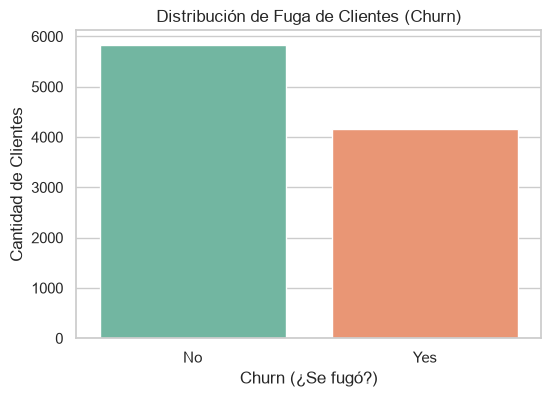

Churn
No     58.31
Yes    41.69
Name: proportion, dtype: float64


In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df, palette='Set2')
plt.title('Distribución de Fuga de Clientes (Churn)')
plt.xlabel('Churn (¿Se fugó?)')
plt.ylabel('Cantidad de Clientes')
plt.show()

print(df['Churn'].value_counts(normalize=True) * 100)

## 4. Detección y Prevención de Data Leakage
Durante la exploración inicial, identificamos que la variable `ChurnReason` contiene el motivo explícito de la baja del cliente. Si se incluye en el entrenamiento, los modelos alcanzan un 100% de acierto artificial (*Data Leakage*). Por lo tanto, se establece que `ChurnReason` y `CustomerID` deben ser excluidos antes de entrenar los modelos predictivos.

## 5. Conclusiones y Próximos Pasos
- El dataset cuenta con **10,000 registros y 35 columnas** limpias y estructuradas.
- Se identificó la necesidad de excluir `ChurnReason` para evitar trampas en el aprendizaje automático.
- Los datos están listos para ser procesados mediante el pipeline modular (`src/telecom_churn/features.py`) y evaluados con los modelos de Machine Learning (Regresión Logística, Random Forest e HistGradientBoosting).